# MNIST data preparation
Images are grayscale `1x28x28` tensors normalized to `[-1, 1]` for the generator's Tanh output and diffusion training. Only the 60,000 MNIST training images are used to fit generators. The 10,000 test images are reserved for the final synthetic-only classifiers. Paths are relative to the project, not the current notebook kernel directory.

In [1]:
import sys
from pathlib import Path
import torch
STARTER = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model/cgan.py').is_file())
sys.path.insert(0, str(STARTER))
from data_utils.dataloader import get_mnist_loaders
from utils.runtime import setup
from utils.visualize import show_batch
from utils.checkpoint import PROJECT_ROOT
device = setup(42)
print('Device:', device)
train_loader, test_loader = get_mnist_loaders(batch_size=128, pin_memory=device.type == 'cuda')
print('Train:', len(train_loader.dataset), 'Test:', len(test_loader.dataset))

Device: cuda
Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9.91M/9.91M [00:00<00:00, 40.8MB/s]


Extracting /workspace/code/project/data/MNIST/raw/train-images-idx3-ubyte.gz to /workspace/code/project/data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 1.04MB/s]

Extracting /workspace/code/project/data/MNIST/raw/train-labels-idx1-ubyte.gz to /workspace/code/project/data/MNIST/raw



Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1.65M/1.65M [00:00<00:00, 8.42MB/s]


Extracting /workspace/code/project/data/MNIST/raw/t10k-images-idx3-ubyte.gz to /workspace/code/project/data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<00:00, 11.5MB/s]

Extracting /workspace/code/project/data/MNIST/raw/t10k-labels-idx1-ubyte.gz to /workspace/code/project/data/MNIST/raw

Train: 60000 Test: 10000


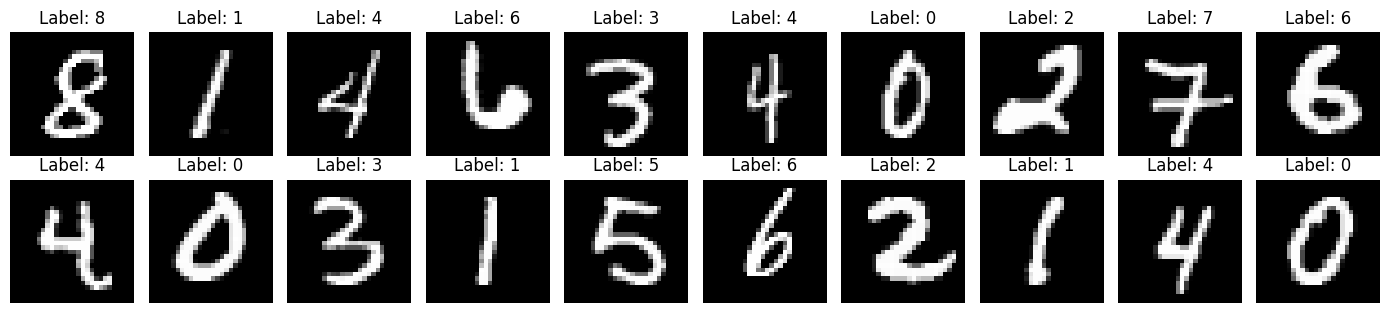

Saved CPU-portable sample batch: /workspace/code/project/data/processed/sample_batch.pt


In [2]:
images, labels = next(iter(train_loader))
assert images.shape[1:] == (1, 28, 28)
assert -1 <= images.min() and images.max() <= 1
show_batch(images, labels, n=20, columns=10)
target = PROJECT_ROOT / 'data/processed/sample_batch.pt'
target.parent.mkdir(parents=True, exist_ok=True)
torch.save({'images': images[:100].cpu(), 'labels': labels[:100].cpu()}, target)
print('Saved CPU-portable sample batch:', target)